# UC Merced Land Use Classification (KNN & SVM)

This notebook classifies aerial images from the **UC Merced Land Use** dataset into **21 land-use categories** (e.g. airplane, beach, forest, freeway, harbor) using classical machine learning.

**Workflow**
1. Import libraries
2. Load images and convert them to feature vectors
3. Split into train and test sets
4. Tune KNN and SVM with `GridSearchCV`
5. Evaluate the best models on unseen data

## 1. Importing libraries

| Library | Purpose |
|---------|---------|
| `cv2` (OpenCV) | read images from disk and resize them |
| `os` | list the dataset folders and files |
| `numpy`, `pandas` | numerical arrays and result tables |
| `matplotlib` | plots (confusion matrix, comparison chart) |
| `scikit-learn` | train/test split, grid search, KNN, SVM, metrics |

In [4]:
# Visualization and image processing
import matplotlib.pyplot as plt
import cv2                      # OpenCV: reading and resizing images
import os                       # walking through dataset folders
import pandas as pd
import numpy as np
from PIL import Image, ImageTk

# Model selection and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score

# Classifiers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

## 2. Loading the dataset

The dataset is organized as one folder per class. For every image the code:

1. reads it with OpenCV (original size 256×256×3),
2. **resizes it to 64×64**, which cuts the data size by 16× and keeps training time reasonable,
3. **flattens** it into a single vector of 64 × 64 × 3 = **12,288 pixel values**, because KNN and SVM expect a 1-D feature vector per sample,
4. stores the folder index as the class label.

Set `folderpath` to the folder containing the 21 class sub-folders on your machine.

In [5]:
# Path to the dataset: one sub-folder per land-use class
folderpath = r"C:\Users\erfun\ax"

x = []   # feature vectors (one flattened image per row)
y = []   # integer class labels

# Each sub-folder is a class; its index (i) becomes the numeric label
for i, j in enumerate(os.listdir(folderpath)):
    path = os.path.join(folderpath, j)
    for b in os.listdir(path):
        path2 = os.path.join(path, b)
        ax = cv2.imread(path2)              # read image as BGR array (256x256x3)
        ax2 = cv2.resize(ax, (64, 64))      # shrink to 64x64 to reduce dimensionality
        ax3 = ax2.flatten()                 # 64*64*3 = 12288 values per image
        x.append(ax3)
        y.append(i)

### Converting to NumPy arrays

scikit-learn works with NumPy arrays, not Python lists. After this step `x` has shape `(2100, 12288)` (images × pixels) and `y` has shape `(2100,)` (one label per image).

In [6]:
# Convert Python lists to NumPy arrays (required by scikit-learn)
x = np.array(x)
y = np.array(y)
print("X shape:", x.shape, "| y shape:", y.shape)

X shape: (500, 12288) | y shape: (500,)


## 3. Train / test split

The data is split **80% / 20%**:
- the **training set** (1,680 images) is used to fit and tune the models,
- the **test set** (420 images) is kept untouched until the final evaluation, so it gives an honest estimate of performance on new images.

`random_state=42` makes the split reproducible.

In [7]:
# 80% of the data for training, 20% for the final test.
# random_state fixes the shuffle so results are reproducible.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Hyperparameter tuning
Two models are tuned with cross-validated grid search: KNN and SVM.

### Setup for tuning

- `class_names` maps numeric labels back to the folder names, used later in reports and plots.
- **Why a `Pipeline`?** Pixel values and distance-based models (KNN, SVM) are sensitive to feature scale. `StandardScaler` centers and scales each feature. Putting it inside a pipeline means that during cross-validation the scaler learns its mean and standard deviation **only from the training folds**, which prevents data leakage from the validation fold.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import time

class_names = os.listdir(folderpath)
print("Train:", x_train.shape, "| Test:", x_test.shape, "| Classes:", len(class_names))

Train: (400, 12288) | Test: (100, 12288) | Classes: 5


## 4. Tuning KNN with GridSearchCV

**K-Nearest Neighbors** classifies an image by looking at its *k* closest training images and voting.

Hyperparameters searched:
- `n_neighbors`: how many neighbors vote (3, 5, 7, 9, 11)
- `weights`: `uniform` (equal votes) or `distance` (closer neighbors count more)
- `metric`: `euclidean` or `manhattan` distance

`GridSearchCV` tries every combination (5 × 2 × 2 = 20) with **5-fold cross-validation** and keeps the one with the best mean accuracy. `n_jobs=-1` uses all CPU cores.

In [9]:
# ---------- KNN ----------
knn_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

knn_params = {
    "knn__n_neighbors": [3, 5, 7, 9, 11],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
}

knn_grid = GridSearchCV(knn_pipe, knn_params, cv=5, scoring="accuracy", n_jobs=-1, verbose=1)
t0 = time.time()
knn_grid.fit(x_train, y_train)
print(f"Time: {time.time() - t0:.1f}s")
print("Best params:", knn_grid.best_params_)
print("Best CV accuracy:", round(knn_grid.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Time: 24.9s
Best params: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Best CV accuracy: 0.385


## 5. Tuning SVM with GridSearchCV

**Support Vector Machine** finds the boundary that best separates the classes, optionally in a higher-dimensional space through a kernel.

Hyperparameters searched:
- `kernel`: `linear` or `rbf` (non-linear)
- `C`: regularization strength. Small values allow more errors but a smoother boundary; large values fit the training data more tightly
- `gamma`: how far the influence of a single sample reaches (only used by `rbf`)

Because SVM is slower on 12,288 features, **3-fold** cross-validation is used here. If this cell takes too long, shorten the lists.

In [10]:
# ---------- SVM ----------
svm_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

svm_params = {
    "svc__kernel": ["linear", "rbf"],
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 1e-5, 1e-4],   # only used by the rbf kernel
}

svm_grid = GridSearchCV(svm_pipe, svm_params, cv=3, scoring="accuracy", n_jobs=-1, verbose=1)
t0 = time.time()
svm_grid.fit(x_train, y_train)
print(f"Time: {time.time() - t0:.1f}s")
print("Best params:", svm_grid.best_params_)
print("Best CV accuracy:", round(svm_grid.best_score_, 4))

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Time: 77.7s
Best params: {'svc__C': 10, 'svc__gamma': 0.0001, 'svc__kernel': 'rbf'}
Best CV accuracy: 0.7


## 6. Evaluating on the test set

Each tuned model (`best_estimator_`, already refit on the full training set) predicts the 420 unseen test images. The table compares:
- **CV accuracy**: average accuracy during cross-validation on training data,
- **Test accuracy**: accuracy on the held-out test set (the number to report).

The `classification_report` gives precision, recall, and F1-score for every class of the best model. A large gap between CV and test accuracy would suggest overfitting.

In [11]:
# ---------- Test set evaluation ----------
results = {}
for name, grid in [("KNN", knn_grid), ("SVM", svm_grid)]:
    pred = grid.best_estimator_.predict(x_test)
    results[name] = {
        "cv_accuracy": grid.best_score_,
        "test_accuracy": accuracy_score(y_test, pred),
        "pred": pred,
    }

summary = pd.DataFrame({k: {"CV accuracy": v["cv_accuracy"], "Test accuracy": v["test_accuracy"]}
                        for k, v in results.items()}).T
print(summary.round(4))

best_name = summary["Test accuracy"].idxmax()
print("\nBest model:", best_name)
print(classification_report(y_test, results[best_name]["pred"], target_names=class_names))

     CV accuracy  Test accuracy
KNN        0.385           0.44
SVM        0.700           0.69

Best model: SVM
              precision    recall  f1-score   support

    airplane       0.83      0.68      0.75        28
       beach       0.78      1.00      0.88        14
   buildings       0.48      1.00      0.65        10
    overpass       0.78      0.58      0.67        24
  parkinglot       0.60      0.50      0.55        24

    accuracy                           0.69       100
   macro avg       0.69      0.75      0.70       100
weighted avg       0.72      0.69      0.69       100



### Confusion matrix

Rows are the true classes and columns the predicted classes. Values on the diagonal are correct predictions; off-diagonal cells show which classes get confused (for example, *dense residential* vs *medium residential*, or *buildings* vs *storage tanks*). The figure is saved as `confusion_matrix.png`.

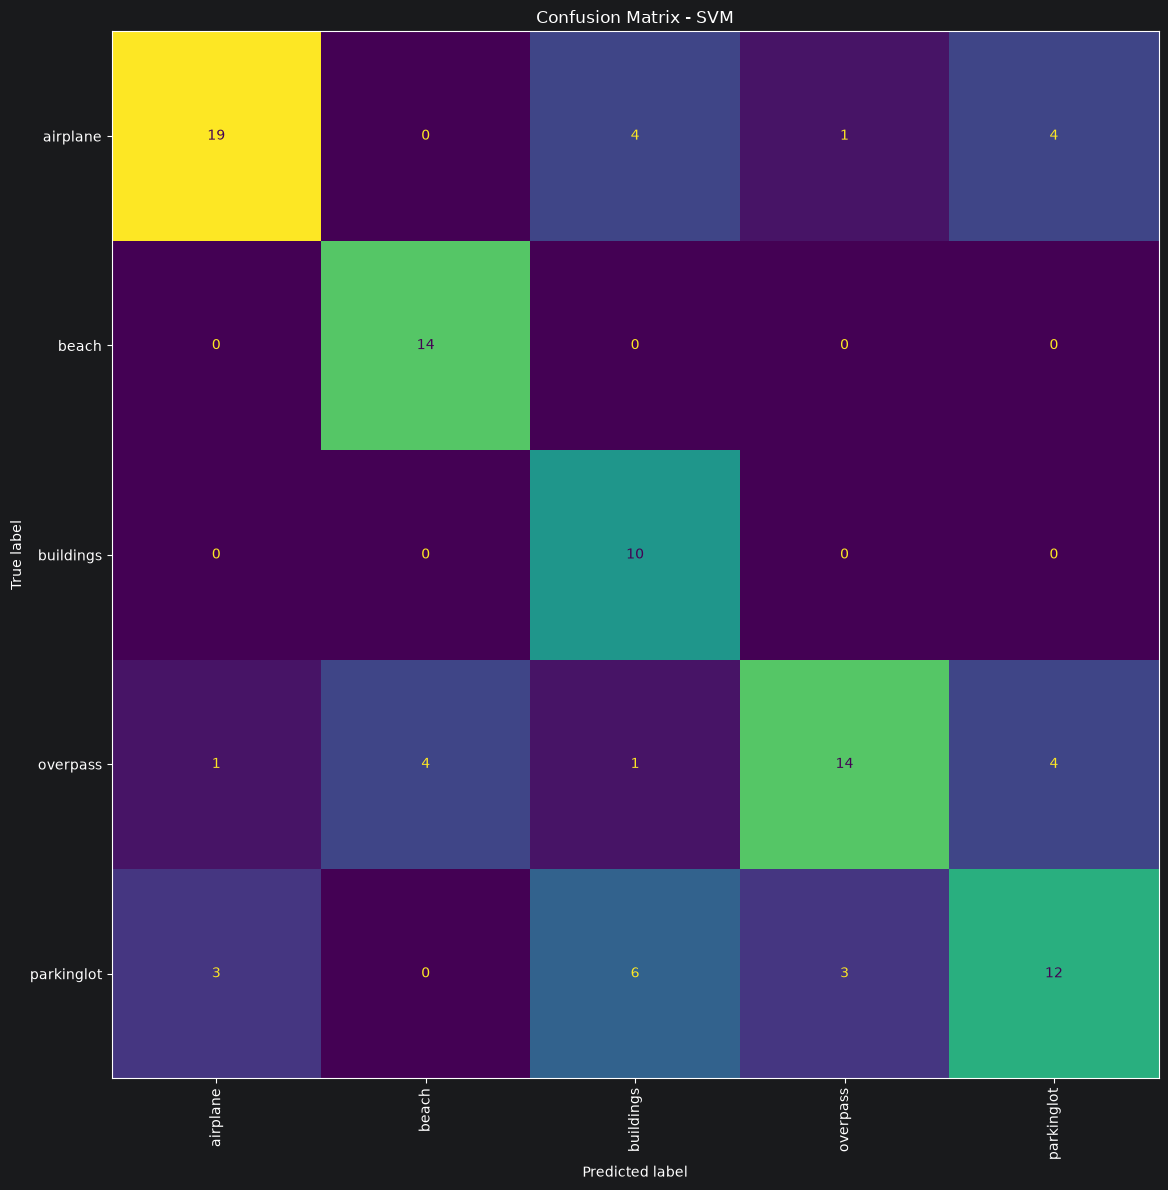

In [12]:
# ---------- Confusion matrix of the best model ----------
cm = confusion_matrix(y_test, results[best_name]["pred"])
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=90, colorbar=False)
plt.title(f"Confusion Matrix - {best_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

### Model comparison

A quick bar chart of cross-validation and test accuracy for KNN and SVM. The figure is saved as `model_comparison.png` for use in the README.

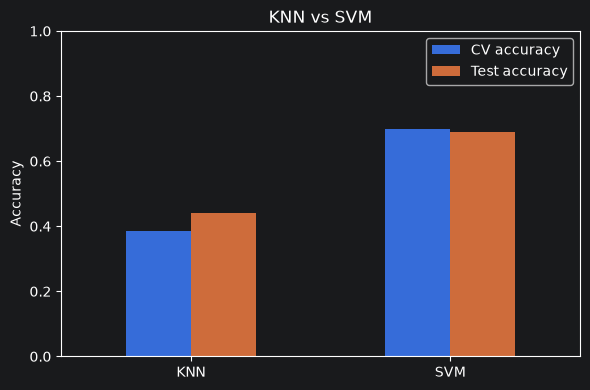

In [13]:
# ---------- Accuracy comparison chart ----------
summary.plot(kind="bar", figsize=(6, 4), ylim=(0, 1))
plt.ylabel("Accuracy")
plt.title("KNN vs SVM")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()